In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


In [24]:
import os

print(os.listdir())

['auto-mpg.data-original', 'NBA IRSHAD 2025', 'pic4.png', 'auto-mpg.data', 'arya s4', 'expt2(1).ipynb', '.ipynb_checkpoints', 'Index', 'pic1.png', 'prajith', 'S1Keerthi', 'inputy2.png', 'pic3.png', 'pic9.png', 'pic10.png', 'pic8.png', 'pic13.png', 'AnanyaS5', 'pic7.png', 'pic11.png', 'pic12.png', 'pic2.png', 'Ards6', 'muflih_s4', 'pic6.png', 'exp 2a.ipynb', 'pic5.png', 'auto-mpg.names', 'linux.txt', 'out1.png']


In [29]:

column_names = [
    'mpg',
    'cylinders',
    'displacement',
    'horsepower',
    'weight',
    'acceleration',
    'model_year',
    'origin'
]

# Load Auto MPG data
df = pd.read_csv(
    "auto-mpg.data",
    sep=r'\s+',
    names=column_names,
    usecols=range(8),
    na_values='?',
    engine='python'
)

# Remove missing values
df = df.dropna()

# Display data
print(df.head())
print("Dataset shape:", df.shape)

# Select feature and target
X = df[['displacement']]
y = df['mpg']

print("X shape:", X.shape)
print("y shape:", y.shape)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   model_year  origin  
0          70       1  
1          70       1  
2          70       1  
3          70       1  
4          70       1  
Dataset shape: (392, 8)
X shape: (392, 1)
y shape: (392,)
Training Samples: 313
Testing Samples: 79


In [30]:
linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, y_train)

# Predict
y_pred_linear = linear_model.predict(X_test)

# Metrics
mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("\n==============================")
print("LINEAR REGRESSION RESULTS")
print("==============================")
print("MSE:", mse_linear)
print("R² Score:", r2_linear)


LINEAR REGRESSION RESULTS
MSE: 21.227484289611397
R² Score: 0.5841057656051312


In [31]:
degrees = [2, 3, 4]

results = []


results.append({
    "Model": "Linear Regression",
    "Degree": 1,
    "MSE": mse_linear,
    "R2 Score": r2_linear
})

polynomial_models = {}

for degree in degrees:

    
    poly = PolynomialFeatures(degree=degree)

    
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    
    poly_model = LinearRegression()
    poly_model.fit(X_train_poly, y_train)

    
    y_pred_poly = poly_model.predict(X_test_poly)

    
    mse_poly = mean_squared_error(y_test, y_pred_poly)
    r2_poly = r2_score(y_test, y_pred_poly)

    
    polynomial_models[degree] = (poly, poly_model)

    
    results.append({
        "Model": "Polynomial Regression",
        "Degree": degree,
        "MSE": mse_poly,
        "R2 Score": r2_poly
    })

    print("\nPolynomial Degree:", degree)
    print("MSE:", mse_poly)
    print("R² Score:", r2_poly)


Polynomial Degree: 2
MSE: 20.649054718307305
R² Score: 0.5954385038809804

Polynomial Degree: 3
MSE: 20.81794078857357
R² Score: 0.5921296453306659

Polynomial Degree: 4
MSE: 20.88841279063398
R² Score: 0.5907489400646382


In [32]:
results_df = pd.DataFrame(results)

print("\n==============================")
print("MODEL COMPARISON")
print("==============================")

print(results_df.to_string(index=False))


MODEL COMPARISON
                Model  Degree       MSE  R2 Score
    Linear Regression       1 21.227484  0.584106
Polynomial Regression       2 20.649055  0.595439
Polynomial Regression       3 20.817941  0.592130
Polynomial Regression       4 20.888413  0.590749


/home/projectlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


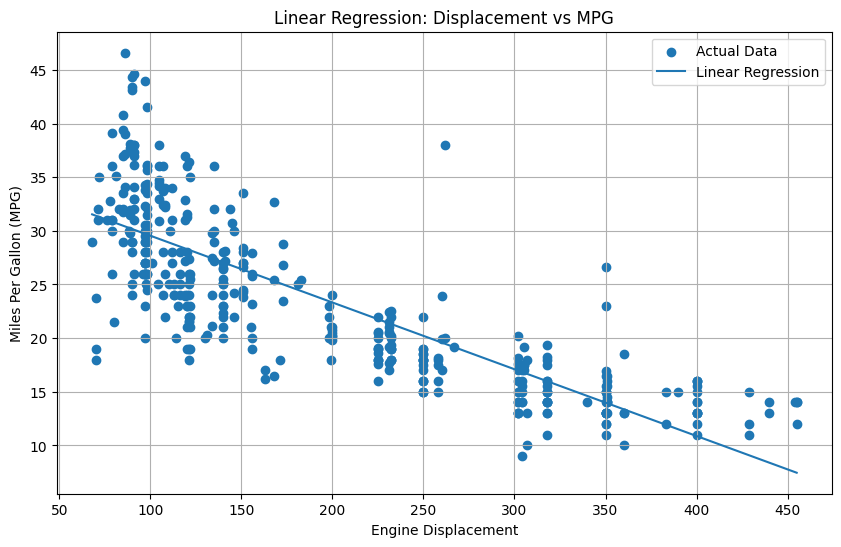

In [33]:
X_sorted = np.sort(X.values, axis=0)

y_linear_line = linear_model.predict(X_sorted)

plt.figure(figsize=(10, 6))

plt.scatter(
    X,
    y,
    label="Actual Data"
)

plt.plot(
    X_sorted,
    y_linear_line,
    label="Linear Regression"
)

plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Linear Regression: Displacement vs MPG")
plt.legend()
plt.grid(True)
plt.show()

/home/projectlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/projectlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/projectlab/.local/lib/python3.8/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


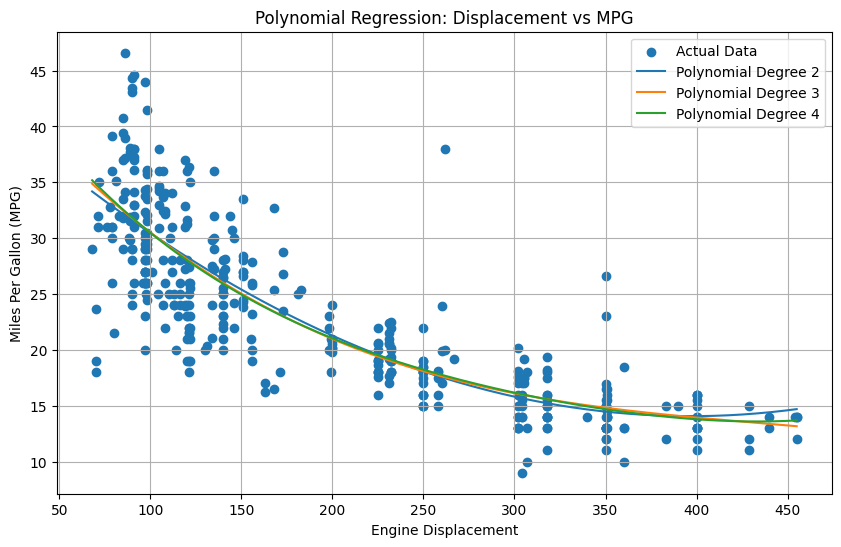

In [34]:
plt.figure(figsize=(10, 6))

# Actual data
plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Smooth X values
X_curve = np.linspace(
    X['displacement'].min(),
    X['displacement'].max(),
    300
).reshape(-1, 1)

# Plot polynomial curves
for degree in degrees:

    poly, poly_model = polynomial_models[degree]

    X_curve_poly = poly.transform(X_curve)

    y_curve = poly_model.predict(X_curve_poly)

    plt.plot(
        X_curve,
        y_curve,
        label=f"Polynomial Degree {degree}"
    )

plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Polynomial Regression: Displacement vs MPG")
plt.legend()
plt.grid(True)
plt.show()